In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import gzip
import json
import collections
import urllib.request

# 1. Define the URL and destination path
url = "https://swarmtraces.org/data/final/redacted.jsonl.gz"
filename = "d.jsonl.gz"

# 2. Add a standard browser User-Agent header to bypass the 403 block
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'})

# 3. Download and save the file
print("Downloading data...")
with urllib.request.urlopen(req) as response, open(filename, 'wb') as out_file:
    out_file.write(response.read())

# --- The rest of your processing script remains the same ---

print("Processing data...")
rows = [json.loads(l) for l in gzip.open(filename, "rt")] 

def flat(d, p=""): 
    out = {} 
    for k, v in d.items(): 
        if isinstance(v, dict): 
            out.update(flat(v, p + k + ".")) 
        else: 
            out[p + k] = v 
    return out 

rows = [flat(r) for r in rows] 
print("rows:", len(rows)) 

for k in sorted({k for r in rows for k in r}): 
    vals = [str(r.get(k)) for r in rows if r.get(k) is not None] 
    d = len(set(vals)) 
    print(f"{k} | present: {len(vals)} | distinct: {d}") 
    if d <= 20: 
        print(" ", collections.Counter(vals).most_common())


Processing data...
rows: 189579
cite | present: 189579 | distinct: 189579
id | present: 189579 | distinct: 189579
kind | present: 189579 | distinct: 3
  [('payload', 91037), ('recovered_text', 75534), ('response', 23008)]
parent_id | present: 61125 | distinct: 26248
tags | present: 189579 | distinct: 35
text | present: 189579 | distinct: 163851
time_utc | present: 0 | distinct: 0
  []


In [3]:
import collections

def tg(r):
    t = r.get("tags")
    return tuple(t) if isinstance(t, list) else (t,)

print("tags type:", type(rows[0]["tags"]))
print("\n-- tag counts --")
for k, v in collections.Counter(tg(r) for r in rows).most_common():
    print(v, k)

print("\n-- kind x tag (top 40) --")
for k, v in collections.Counter((r["kind"], tg(r)) for r in rows).most_common(40):
    print(v, k)

by_id = {r["id"]: r for r in rows}
print("\n-- parent kind -> child kind --")
pc = collections.Counter(
    (by_id[r["parent_id"]]["kind"] if r["parent_id"] in by_id else "missing", r["kind"])
    for r in rows if r.get("parent_id"))
print(pc.most_common())

def depth(r):
    d, seen = 0, set()
    while r.get("parent_id") and r["parent_id"] in by_id and r["id"] not in seen:
        seen.add(r["id"]); r = by_id[r["parent_id"]]; d += 1
    return d

print("\n-- chain depth --")
print(collections.Counter(depth(r) for r in rows).most_common(15))

tags type: <class 'str'>

-- tag counts --
189542 ('',)
3 ('article-evidence;appendix-request',)
2 ('article-evidence;g236-command;g23619cmd.bin;command-000007',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000001',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000002',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000003',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000004',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000005',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000006',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000008',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000009',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000010',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000011',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000012',)
1 ('article-evidence;g236-command;g23619cmd.bin;command-000013',)
1 ('article-evidence;g236-command;g23619cmd.b

In [4]:
import re, collections
def norm(t):
    t = re.sub(r'\[[^\]]*\]', '[X]', t)
    t = re.sub(r'[0-9a-fA-F]{8,}', 'H', t)
    return re.sub(r'\d+', 'N', t)

pay = [r for r in rows if r['kind'] == 'payload']
fam = collections.Counter(norm(r['text']) for r in pay)
sizes = sorted(fam.values(), reverse=True)
print(len(pay), "payloads ->", len(fam), "families")
print("top 10 family sizes:", sizes[:10])
print("share in top 50 families:", sum(sizes[:50]) / len(pay))
print("singleton families:", sum(1 for s in sizes if s == 1))

91037 payloads -> 39495 families
top 10 family sizes: [3301, 3265, 3015, 2664, 2663, 2606, 2291, 2265, 1486, 1203]
share in top 50 families: 0.402913101266518
singleton families: 35998


In [5]:
import re, collections

pay = [r for r in rows if r['kind'] == 'payload']

def base(t):
    t = re.sub(r'\[[^\]]*\]', '[X]', t)          # redaction placeholders
    t = re.sub(r'[0-9a-fA-F]{8,}', 'H', t)       # long hex IDs / hashes
    return re.sub(r'\d+', 'N', t)                # numbers

def strict(t):                                    # what we already ran
    return base(t)

def medium(t):                                    # also mask string contents
    t = base(t)
    t = re.sub(r"'[^'\n]*'|\"[^\"\n]*\"", "S", t)
    return re.sub(r'\s+', ' ', t).strip()

def loose(t):                                     # set of calls and attribute names
    calls = re.findall(r'\.?[A-Za-z_][A-Za-z_0-9]*(?=\s*\()', t)
    attrs = re.findall(r'\.[A-Za-z_][A-Za-z_0-9]*', t)
    return ' '.join(sorted(set(calls + attrs)))

def report(name, fn):
    keys = [fn(r['text']) for r in pay]
    fam = collections.Counter(keys)
    sizes = sorted(fam.values(), reverse=True)
    single = sum(1 for s in sizes if s == 1)
    empty = fam.get('', 0)
    print(f"{name}: {len(fam)} families | top10 {sizes[:10]}")
    print(f"   top-50 share {sum(sizes[:50])/len(pay):.3f} | "
          f"singleton families {single} ({single/len(pay):.3f} of payloads) | "
          f"empty-key payloads {empty}")
    return keys

K_strict = report("strict", strict)
K_medium = report("medium", medium)
K_loose  = report("loose", loose)

strict: 39495 families | top10 [3301, 3265, 3015, 2664, 2663, 2606, 2291, 2265, 1486, 1203]
   top-50 share 0.403 | singleton families 35998 (0.395 of payloads) | empty-key payloads 0
medium: 34270 families | top10 [7573, 5057, 3558, 3140, 2979, 2404, 1963, 1516, 1180, 996]
   top-50 share 0.441 | singleton families 30002 (0.330 of payloads) | empty-key payloads 1
loose: 20535 families | top10 [18743, 9936, 5613, 5037, 3387, 1187, 772, 674, 602, 531]
   top-50 share 0.580 | singleton families 15663 (0.172 of payloads) | empty-key payloads 9936


In [6]:
empty = [r for r in pay if loose(r['text']) == '']
print(len(empty))
print("first word:", collections.Counter(re.match(r'\s*(\S{1,12})', r['text']).group(1) if r['text'].strip() else '' for r in empty).most_common(10))
lens = sorted(len(r['text']) for r in empty)
print("length min/median/max:", lens[0], lens[len(lens)//2], lens[-1])
print("share with no '(' at all:", sum('(' not in r['text'] for r in empty) / len(empty))

9936
first word: [('[SERVICE', 2775), ('[PROXY', 2118), ('https://[RED', 1178), ('[ENCODED', 753), ('<iframe', 552), ('[SHORTENER', 373), ('redirect', 308), ("location='[S", 224), ('http://[REDA', 212), ("location='ht", 177)]
length min/median/max: 1 71 8969
share with no '(' at all: 0.9626610305958132


In [7]:
import random, csv
random.seed(42)

fam = collections.Counter(K_medium)
by_fam = collections.defaultdict(list)
for r, k in zip(pay, K_medium):
    by_fam[k].append(r)

big = [k for k, _ in fam.most_common(15)]
small = random.sample([k for k, v in fam.items() if v <= 2], 15)

sample = []
for group, keys in [("big", big), ("small", small)]:
    for k in keys:
        r = by_fam[k][0]
        sample.append((r['id'], group, fam[k], r['text'][:200].replace("\n", " ")))

with open("to_label.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["id", "group", "family_size", "snippet", "your_label"])
    w.writerows([list(s) + [""] for s in sample])

for s in sample:
    print(s[0], s[1], s[2], "|", s[3][:120])

R0119023 big 7573 | [SERVICE 3 URL 209][ENCODED BLOB 73157][REDACTED:opaque_marker_tail:000008]   x+='[REDACTED:opaque_fragment:003332]';n('
R0118983 big 5057 | [PROXY 4 URL 72][ENCODED BLOB 73114]   x+='[ENCODED BLOB 73115]';n('//[SHORTENER URL 150370]')
R0002331 big 3558 | ── stage: A[] batch (8 slots) ── [ENCODED BLOB 278]
R0119000 big 3140 | [PROXY 4 URL 72][ENCODED BLOB 73130][REDACTED:opaque_marker_tail:000007]   x+='[REDACTED:opaque_fragment:003328]';docume
R0014341 big 2979 | for(s of'[SHORTENER CODE 21277],[SHORTENER CODE 21278],[SHORTENER CODE 21279]'.split(','))document.write('<script src=[R
R0003484 big 2404 | x+='[REDACTED:opaque_fragment:000018]';n('[SHORTENER CODE 3720]') 
R0000312 big 1963 | document.write('<script src=[REDACTED:destination:000003][SHORTENER URL 34]></script><script src=[REDACTED:destination:0
R0000320 big 1516 | [SERVICE 2 URL 3]
R0014671 big 1180 | x=(self.x||'')+'[ENCODED BLOB]';document.write('<script src=[REDACTED:destination:000003][SHORTENER URL 

In [8]:
carrier_pat = re.compile(
    r"x\+=|x\[\d+\]=|\bn\('|<script src|<iframe src|stage: |"
    r"^\s*redirect|location\s*=|^\s*\[(SERVICE|PROXY|SHORTENER)[^\]]*\]|^\s*https?://\[RED")

def is_plumbing(t):
    return bool(carrier_pat.search(t))

flag = [is_plumbing(r['text']) for r in pay]
print("plumbing payloads:", sum(flag), "of", len(pay), f"({sum(flag)/len(pay):.2f})")

# sanity check against your 30 labels
carriers = "R0119023 R0118983 R0002331 R0119000 R0014341 R0003484 R0000312 R0014671 R0118969 R0081260 R0008134 R0018490 R0016172 R0014472 R0049300 R0121784".split()
content = "R0001272 R0006244 R0052934 R0007598 R0009201".split()
by_id = {r['id']: r for r in pay}
print("carriers caught:", sum(is_plumbing(by_id[i]['text']) for i in carriers), "of", len(carriers))
print("content wrongly flagged:", sum(is_plumbing(by_id[i]['text']) for i in content), "of", len(content))

rest = [r for r, f in zip(pay, flag) if not f]
fam_rest = collections.Counter(medium(r['text']) for r in rest)
sizes = sorted(fam_rest.values(), reverse=True)
print("remaining payloads:", len(rest), "| families:", len(fam_rest))
print("top 10 sizes:", sizes[:10])
print("singleton families:", sum(1 for s in sizes if s == 1))

plumbing payloads: 56610 of 91037 (0.62)
carriers caught: 16 of 16
content wrongly flagged: 0 of 5
remaining payloads: 34427 | families: 22355
top 10 sizes: [806, 223, 202, 172, 160, 160, 155, 151, 147, 134]
singleton families: 19295


In [9]:
random.seed(7)
flag_rows = [r for r, f in zip(pay, flag) if f]
rest_rows = [r for r, f in zip(pay, flag) if not f]

for name, rows_ in [("CALLED PLUMBING", flag_rows), ("CALLED REAL CONTENT", rest_rows)]:
    print("\n=====", name, "=====")
    for r in random.sample(rows_, 20):
        print(r['id'], "|", r['text'][:100].replace("\n", " "))


===== CALLED PLUMBING =====
R0079889 | [PROXY 4 URL 72][ENCODED BLOB 55080]   https://datasets-server.huggingface.co/splits?dataset=[REDACT
R0027420 | ── stage: A[] batch (8 slots) ── [ENCODED BLOB 19482]
R0116606 | [SERVICE HOST 25][ENCODED BLOB 67823]-[ENCODED BLOB 67824]-[ENCODED BLOB 67825][REDACTED:opaque_mark
R0133684 | [SERVICE 3 URL 209][ENCODED BLOB 90052][REDACTED:opaque_marker_tail:000015]   x+='[ENCODED BLOB 9005
R0010736 | for(s of'[SHORTENER CODE 16866] [SHORTENER CODE 16867] [SHORTENER CODE 16868] [SHORTENER CODE 16887]
R0015069 | ── stage: A[] batch (8 slots) ── [ENCODED BLOB 7769][ENCODED BLOB 2074][ENCODED BLOB 7770]
R0144855 | [SERVICE 3 URL 209][ENCODED BLOB 104648][REDACTED:opaque_marker_tail:000008]   x+='[REDACTED:opaque_
R0126136 | [SERVICE HOST 25]/base64/[ENCODED BLOB 80260]   C+='[ENCODED BLOB]';L('ajf')
R0018402 | ── stage: A[] batch (8 slots) ── c7d\",\"function_name\":\"sqlite3_initialize\",\"file_path\":\"src/
R0114681 | x+='[ENCODED BLOB 66068]';n('[RED

In [10]:
carrier_pat = re.compile(
    carrier_pat.pattern + r"|^\s*a=\[\];|^\s*[A-Za-z]=\[\"\[SHORTENER")

flag = [is_plumbing(r['text']) for r in pay]
print("plumbing payloads:", sum(flag), "of", len(pay), f"({sum(flag)/len(pay):.2f})")
print("fixed rows now flagged:", is_plumbing(by_id['R0044367']['text']), is_plumbing(by_id['R0005122']['text']))

plumbing payloads: 56988 of 91037 (0.63)
fixed rows now flagged: True True


In [11]:
random.seed(11)
rest = [r for r, f in zip(pay, flag) if not f]
K = [medium(r['text']) for r in rest]
fam = collections.Counter(K)

by_fam = collections.defaultdict(list)
for r, k in zip(rest, K):
    by_fam[k].append(r)

big = [k for k, _ in fam.most_common(30)]
small = random.sample([k for k, v in fam.items() if v <= 2], 70)

out = []
for group, keys in [("big", big), ("small", small)]:
    for k in keys:
        r = by_fam[k][0]
        out.append([r['id'], group, fam[k], r['text'][:150].replace("\n", " "), ""])

with open("to_label_100.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["id", "group", "family_size", "snippet", "your_label"])
    w.writerows(out)
print(len(out), "rows saved to to_label_100.csv")

100 rows saved to to_label_100.csv


In [12]:
carrier_pat = re.compile(carrier_pat.pattern +
    r"|^\s*[A-Za-z]\[\d+\]\s*=|top\.A|^\s*[A-Za-z]=\[\];|^\s*d=\[\];n=0;s="
    r"|^\s*[A-Za-z]\('\[SHORTENER|^\s*httpbun\.com|^\s*\[ENCODED BLOB\]\s*$")

flag = [is_plumbing(r['text']) for r in pay]
print("plumbing:", sum(flag), "of", len(pay), f"({sum(flag)/len(pay):.2f})")
rest = [r for r, f in zip(pay, flag) if not f]
fam_rest = collections.Counter(medium(r['text']) for r in rest)
print("behavior payloads:", len(rest), "| families:", len(fam_rest))
print("top 10 sizes:", sorted(fam_rest.values(), reverse=True)[:10])

plumbing: 59259 of 91037 (0.65)
behavior payloads: 31778 | families: 21595
top 10 sizes: [408, 172, 160, 155, 151, 147, 134, 121, 111, 99]


In [13]:
opaque_pat = re.compile(r"^\s*\[[^\]]*\]\s*$")
opaque = [bool(opaque_pat.match(r['text'])) and not f for r, f in zip(pay, flag)]
print("single-placeholder payloads not yet flagged:", sum(opaque))

def placeholder_kind(t):
    m = re.match(r"\s*\[\s*([^\]\s\d]+(?:\s[^\]\s\d]+)*)", t)   # words before any number
    return m.group(1) if m else "<other>"

print(collections.Counter(placeholder_kind(r['text'])
      for r, o in zip(pay, opaque) if o).most_common(8))

rest = [r for r, f, o in zip(pay, flag, opaque) if not f and not o]
fam_rest = collections.Counter(medium(r['text']) for r in rest)
print("behavior payloads:", len(rest), "| families:", len(fam_rest))
print("top 10 sizes:", sorted(fam_rest.values(), reverse=True)[:10])

single-placeholder payloads not yet flagged: 408
[('ENCODED BLOB', 182), ('ORIGINAL ENCODED CONTENT-RETRIEVAL TEST; OPAQUE CARRIER AND UNRELATED STATIC BODY REDACTED', 120), ('REDACTED OPAQUE BINARY CONTENT', 80), ('REDACTED:destination:', 6), ('ORIGINAL OPAQUE ECHO OR DELIVERY TEST; UNDECODED CARRIER REDACTED', 5), ('REDIRECT URL', 4), ('REDACTED:opaque_base', 2), ('WEBHOOK', 2)]
behavior payloads: 31370 | families: 21594
top 10 sizes: [172, 160, 155, 151, 147, 134, 121, 111, 99, 81]


In [14]:
import random, csv, collections

random.seed(42)   # fixed seed = reproducible sample (report this)

# --- assign each payload to a stratum ---
rows = []
for i, (r, f, o) in enumerate(zip(pay, flag, opaque)):
    rows.append({
        "idx": i,
        "row_id": r.get("id", f"R{i:07d}"),
        "text": r["text"],
        "rule_pred": "plumbing" if f else ("opaque" if o else "behavior"),
    })

beh = [x for x in rows if x["rule_pred"] == "behavior"]
fam_of = {x["idx"]: medium(x["text"]) for x in beh}
fam_size = collections.Counter(fam_of.values())
top_fams = {fam for fam, _ in fam_size.most_common(30)}

pools = {
    "plumbing":   [x for x in rows if x["rule_pred"] == "plumbing"],
    "opaque":     [x for x in rows if x["rule_pred"] == "opaque"],
    "beh_big":    [x for x in beh if fam_of[x["idx"]] in top_fams],
    "beh_tail":   [x for x in beh if fam_of[x["idx"]] not in top_fams],
}
quota = {"plumbing": 25, "opaque": 5, "beh_big": 40, "beh_tail": 30}

# --- for big families, spread picks across families (max 2 per family) ---
def sample_spread(pool, n, per_fam=2):
    random.shuffle(pool)
    out, used = [], collections.Counter()
    for x in pool:
        fam = fam_of.get(x["idx"])
        if used[fam] < per_fam:
            out.append(x); used[fam] += 1
        if len(out) == n: break
    return out

sample = []
for s, n in quota.items():
    picked = sample_spread(pools[s], n) if s == "beh_big" else random.sample(pools[s], n)
    for x in picked:
        x["stratum"] = s
        x["family"] = fam_of.get(x["idx"], "")
    sample += picked

random.shuffle(sample)   # mix strata so order gives no hints

# --- file 1: what YOU label (blind) ---
with open("label_sheet.csv", "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["row_id", "text_first_700_chars", "your_label", "notes"])
    for x in sample:
        w.writerow([x["row_id"], x["text"][:700], "", ""])

# --- file 2: the answer key (DON'T open until you finish labeling) ---
with open("label_key_hidden.csv", "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["row_id", "stratum", "rule_pred", "family"])
    for x in sample:
        w.writerow([x["row_id"], x["stratum"], x["rule_pred"], x["family"]])

print(len(sample), "rows written")
print(collections.Counter(x["stratum"] for x in sample))

100 rows written
Counter({'beh_big': 40, 'beh_tail': 30, 'plumbing': 25, 'opaque': 5})


In [15]:
import pandas as pd, io

code = {"C":"chunk_carrier","D":"delivery_stub","H":"hf_access","R":"recon",
        "K":"credential_access","O":"opaque","X":"other_behavior","U":"unclear"}
raw = """R0019774 H|R0028511 D|R0130288 C|R0037841 H|R0047416 K|R0014952 H|R0000006 R|R0051434 H|R0132731 C|R0025254 H
R0026749 H|R0035846 X|R0034327 H|R0118201 O|R0018762 H|R0018331 C|R0117798 O|R0017568 H|R0029729 H|R0007934 R
R0039972 H|R0017544 X|R0032449 C|R0013927 H|R0112961 X|R0017133 C|R0136649 C|R0127836 C|R0116937 O|R0022589 H
R0000122 R|R0039639 H|R0042419 X|R0035247 H|R0124122 D|R0031103 H|R0012752 H|R0032944 H|R0042855 H|R0011494 H
R0038799 H|R0127081 C|R0146854 C|R0000640 X|R0041427 H|R0115890 C|R0011450 H|R0113104 X|R0031307 H|R0010578 H
R0003637 R|R0017503 H|R0121498 C|R0016337 H|R0051576 K|R0025775 H|R0045314 U|R0136925 C|R0032815 C|R0020126 H
R0018124 H|R0003085 X|R0006177 R|R0035369 X|R0009147 X|R0005127 D|R0022285 C|R0050659 R|R0003114 X|R0023989 X
R0030044 O|R0017147 H|R0015838 H|R0022539 H|R0022559 H|R0035034 H|R0004415 C|R0004519 C|R0014938 C|R0006705 X
R0039261 C|R0023011 H|R0004937 C|R0045020 H|R0052078 O|R0045898 H|R0045478 D|R0034357 C|R0035029 H|R0025344 R
R0033331 C|R0118070 O|R0047979 H|R0052727 X|R0046737 R|R0021351 H|R0044197 H|R0041003 H|R0136983 C|R0033164 H"""
pairs = [p.split() for line in raw.splitlines() for p in line.split("|")]
labels = pd.DataFrame([(a, code[b]) for a, b in pairs], columns=["row_id","label"])
print(len(labels), labels.label.value_counts().to_dict())

100 {'hf_access': 44, 'chunk_carrier': 22, 'other_behavior': 13, 'recon': 8, 'opaque': 6, 'delivery_stub': 4, 'credential_access': 2, 'unclear': 1}


In [16]:
import numpy as np
key = pd.read_csv("label_key_hidden.csv")
df = key.merge(labels, on="row_id")
to_rule = {"chunk_carrier":"plumbing","delivery_stub":"plumbing","opaque":"opaque"}
df["label_rule_space"] = df.label.map(lambda x: to_rule.get(x, "behavior"))
df = df[df.label != "unclear"]          # exclude unclear from accuracy, report the count

acc = (df.rule_pred == df.label_rule_space).mean()
print(f"Rule accuracy vs labels: {acc:.2f} on n={len(df)}")
print(pd.crosstab(df.label_rule_space, df.rule_pred, rownames=["label"], colnames=["rule"]))

print("\nAccuracy by stratum:")
print(df.assign(ok=df.rule_pred==df.label_rule_space).groupby("stratum").ok.agg(["mean","count"]))

# bootstrap 95% CI
rng = np.random.default_rng(0)
ok = (df.rule_pred == df.label_rule_space).values
bs = [rng.choice(ok, len(ok)).mean() for _ in range(2000)]
print("95% CI:", np.percentile(bs, [2.5, 97.5]).round(2))

# error analysis: where do they disagree?
bad = df[df.rule_pred != df.label_rule_space]
print("\nDisagreements:")
print(bad[["row_id","stratum","rule_pred","label","family"]].to_string())

Rule accuracy vs labels: 0.94 on n=99
rule      behavior  opaque  plumbing
label                               
behavior        65       0         2
opaque           1       5         0
plumbing         3       0        23

Accuracy by stratum:
              mean  count
stratum                  
beh_big   0.925000     40
beh_tail  0.965517     29
opaque    1.000000      5
plumbing  0.920000     25
95% CI: [0.89 0.98]

Disagreements:
      row_id   stratum rule_pred           label                                                                                                                                                                                                                                                                    family
1   R0028511   beh_big  behavior   delivery_stub                                                                                                                                                                                                        

In [17]:
N = {s: len(p) for s, p in pools.items()}     # real stratum sizes
tot = sum(N.values())
print("Stratum sizes:", N, "| total:", tot)

d = df.copy()
d["ok"]         = d.rule_pred == d.label_rule_space
d["true_plumb"] = d.label_rule_space == "plumbing"

def weighted(d, col):
    return sum(N[s] * d[d.stratum == s][col].mean() for s in N) / tot

acc_w   = weighted(d, "ok")
plumb_w = weighted(d, "true_plumb")      # corrected plumbing share
print(f"Weighted rule accuracy:        {acc_w:.3f}")
print(f"Rule's plumbing share:         {59259/tot:.3f}")
print(f"Estimated TRUE plumbing share: {plumb_w:.3f}")

# stratified bootstrap: resample within each stratum
rng = np.random.default_rng(0)
groups = {s: d[d.stratum == s] for s in N}
accs, plumbs = [], []
for _ in range(2000):
    a = p = 0
    for s, g in groups.items():
        r = g.iloc[rng.integers(0, len(g), len(g))]
        a += N[s] * r.ok.mean()
        p += N[s] * r.true_plumb.mean()
    accs.append(a / tot); plumbs.append(p / tot)
print("Accuracy 95% CI:       ", np.percentile(accs,   [2.5, 97.5]).round(3))
print("True plumbing share CI:", np.percentile(plumbs, [2.5, 97.5]).round(3))

Stratum sizes: {'plumbing': 59259, 'opaque': 408, 'beh_big': 2336, 'beh_tail': 29034} | total: 91037
Weighted rule accuracy:        0.935
Rule's plumbing share:         0.651
Estimated TRUE plumbing share: 0.601
Accuracy 95% CI:        [0.857 0.998]
True plumbing share CI: [0.523 0.653]


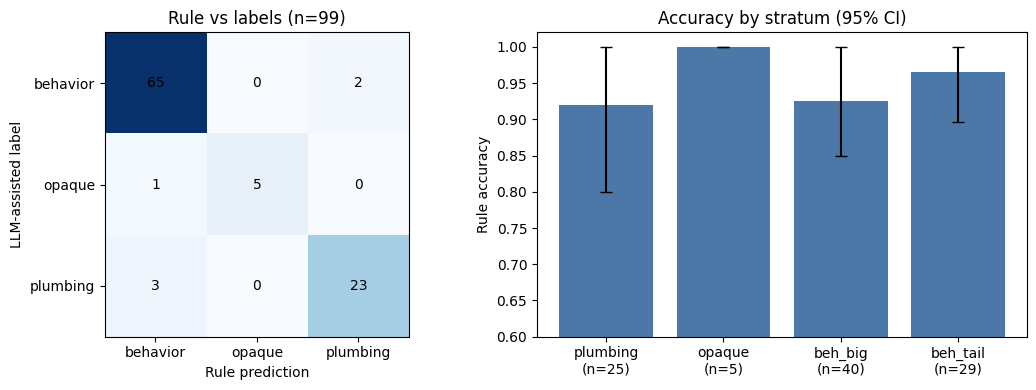

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Fig 1: confusion matrix
cm = pd.crosstab(d.label_rule_space, d.rule_pred)
im = ax[0].imshow(cm.values, cmap="Blues")
ax[0].set_xticks(range(len(cm.columns)), cm.columns)
ax[0].set_yticks(range(len(cm.index)), cm.index)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax[0].text(j, i, cm.values[i, j], ha="center", va="center")
ax[0].set_xlabel("Rule prediction"); ax[0].set_ylabel("LLM-assisted label")
ax[0].set_title("Rule vs labels (n=99)")

# Fig 2: accuracy by stratum with 95% CI (bootstrap)
names, means, lo, hi = [], [], [], []
for s, g in groups.items():
    bs = [g.ok.values[rng.integers(0, len(g), len(g))].mean() for _ in range(2000)]
    names.append(f"{s}\n(n={len(g)})"); means.append(g.ok.mean())
    lo.append(g.ok.mean() - np.percentile(bs, 2.5)); hi.append(np.percentile(bs, 97.5) - g.ok.mean())
ax[1].bar(names, means, yerr=[lo, hi], capsize=4, color="#4C78A8")
ax[1].set_ylim(0.6, 1.02); ax[1].set_ylabel("Rule accuracy")
ax[1].set_title("Accuracy by stratum (95% CI)")

plt.tight_layout(); plt.savefig("fig_rule_eval.png", dpi=200); plt.show()

In [19]:
import os
print(os.path.abspath("fig_rule_eval.png"), os.path.exists("fig_rule_eval.png"))
try:
    from google.colab import files; files.download("fig_rule_eval.png")   # Colab
except ImportError:
    pass   # Kaggle/Jupyter: open the file panel on the right/left, find fig_rule_eval.png, download it

/kaggle/working/fig_rule_eval.png True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
labs = sorted(d.label.unique())
rng = np.random.default_rng(0)

def est(groups):
    out = {}
    for L in labs:
        out[L] = sum(N[s] * (g.label == L).mean() for s, g in groups.items()) / tot
    return out

point = est(groups)

# stratified bootstrap for 95% CIs
boots = {L: [] for L in labs}
for _ in range(2000):
    resampled = {s: g.iloc[rng.integers(0, len(g), len(g))] for s, g in groups.items()}
    e = est(resampled)
    for L in labs:
        boots[L].append(e[L])

res = pd.DataFrame({
    "share": {L: point[L] for L in labs},
    "ci_low": {L: np.percentile(boots[L], 2.5) for L in labs},
    "ci_high": {L: np.percentile(boots[L], 97.5) for L in labs},
}).sort_values("share", ascending=False).round(3)
print(res)

# share among BEHAVIOR only (drop plumbing and opaque)
beh_labels = [L for L in labs if L not in ("chunk_carrier", "delivery_stub", "opaque")]
tot_beh = sum(point[L] for L in beh_labels)
print("\nShare within behavior payloads:")
print((res.loc[beh_labels, "share"] / tot_beh).round(3).sort_values(ascending=False))

                   share  ci_low  ci_high
chunk_carrier      0.547   0.443    0.626
hf_access          0.219   0.149    0.302
other_behavior     0.106   0.039    0.186
delivery_stub      0.053   0.001    0.131
recon              0.036   0.004    0.080
credential_access  0.022   0.000    0.055
opaque             0.015   0.004    0.037

Share within behavior payloads:
hf_access            0.571
other_behavior       0.276
recon                0.094
credential_access    0.057
Name: share, dtype: float64
